# **Iris Multi-Layer Perceptron (MLP) Ablation Study**
### *Empirical Hyperparameter Optimization & Systematic Benchmarks*
**Author:** Raza e Mustafa


In [9]:
!pip install --upgrade tensorflow

### 1. Imports and Data Preparation

In [1]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, regularizers, initializers
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, log_loss

warnings.filterwarnings("ignore")

# Stratified 60/20/20 (90/30/30), Scaler fit on Train ONLY
X, y = load_iris(return_X_y=True)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

scaler = StandardScaler().fit(X_train) # Fit ONLY on train -> zero data leakage
X_train, X_val, X_test = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
print(f"Split sizes -> Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Split sizes -> Train: 90, Val: 30, Test: 30


### 2. Experiment Specifications

In [2]:
EXPERIMENTS = {
    "E0: Baseline":           dict(init="glorot_uniform", l2=0.0,  dropout=0.0, lr=0.001),
    "E1: Initialization":     dict(init="he_normal",      l2=0.0,  dropout=0.0, lr=0.001),
    "E2: L2":                 dict(init="glorot_uniform", l2=0.01, dropout=0.0, lr=0.001),
    "E3: Dropout":            dict(init="glorot_uniform", l2=0.0,  dropout=0.3, lr=0.001),
    "E4: Combined":           dict(init="glorot_uniform", l2=0.01, dropout=0.3, lr=0.001),
    "E5: Low learning rate":  dict(init="glorot_uniform", l2=0.01, dropout=0.3, lr=0.0001),
    "E6: High learning rate": dict(init="glorot_uniform", l2=0.01, dropout=0.3, lr=0.01),
}
SEEDS = [0, 1, 2]
MAX_EPOCHS = 200

### 3. Model Builder Helper Functions

In [3]:
def set_seed(s):
    os.environ['PYTHONHASHSEED'] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

def build_model(init, l2, dropout, lr):
    # Lecture rule: L2 applies ONLY to weights (kernel_regularizer), NOT bias
    reg = regularizers.l2(l2) if l2 > 0 else None
    ini = initializers.get(init)
    m = tf.keras.Sequential([
        layers.Input(shape=(4,)),
        layers.Dense(64, activation="relu", kernel_initializer=ini, kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(32, activation="relu", kernel_initializer=ini, kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(3, activation="softmax", kernel_initializer=ini),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

### 4. Run All Experiments

In [4]:
rows, histories = [], {}
for name, cfg in EXPERIMENTS.items():
    for seed in SEEDS:
        set_seed(seed)
        model = build_model(**cfg)
        es = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=15, restore_best_weights=True
        )
        t0 = time.time()
        h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=MAX_EPOCHS, batch_size=16, callbacks=[es], verbose=0)
        train_time = time.time() - t0

        probs = model.predict(X_test, verbose=0)
        pred = np.argmax(probs, axis=1)

        # Pure Cross-Entropy Test Loss
        pure_test_loss = log_loss(y_test, probs)

        rows.append(dict(
            Experiment=name, Seed=seed,
            Epochs_run=len(h.history["loss"]),
            Best_epoch=int(np.argmin(h.history["val_loss"])) + 1,
            Test_acc=accuracy_score(y_test, pred),
            Test_macro_F1=f1_score(y_test, pred, average="macro"),
            Test_loss=pure_test_loss,
            Time_s=train_time
        ))
        if seed == SEEDS[0]:
            histories[name] = h.history
    print(f"Completed: {name}")

df = pd.DataFrame(rows)

Completed: E0: Baseline


Completed: E1: Initialization
Completed: E2: L2
Completed: E3: Dropout
Completed: E4: Combined
Completed: E5: Low learning rate
Completed: E6: High learning rate


### 5. Summary Table

In [5]:
print("\n=== Mean ± Std Over 3 Seeds ===")
summary = df.groupby("Experiment", sort=False)[
    ["Epochs_run", "Best_epoch", "Test_acc", "Test_macro_F1", "Test_loss", "Time_s"]
].agg(["mean", "std"]).round(4)
display(summary)


=== Mean ± Std Over 3 Seeds ===


Epochs_run          Best_epoch          Test_acc  \
                             mean      std       mean      std     mean   
Experiment                                                                
E0: Baseline             144.3333  48.5215   133.3333  55.4106   0.9222   
E1: Initialization        39.6667  10.5040    24.6667  10.5040   0.8333   
E2: L2                   200.0000   0.0000   200.0000   0.0000   0.9333   
E3: Dropout               78.6667   9.0185    63.6667   9.0185   0.9000   
E4: Combined             199.0000   1.7321   188.6667   6.5064   0.9333   
E5: Low learning rate    200.0000   0.0000   200.0000   0.0000   0.7778   
E6: High learning rate    47.0000   6.9282    32.0000   6.9282   0.9333   

                               Test_macro_F1         Test_loss          \
                           std          mean     std      mean     std   
Experiment                                                               
E0: Baseline            0.0192        0.9221  0.0194    0.1812  0.0258   
E1: Initialization      0.0333        0.8288  0.0368    0.2994  0.0135   
E2: L2                  0.0000        0.9333  0.0000    0.1158  0.0053   
E3: Dropout             0.0000        0.8997  0.0000    0.2152  0.0174   
E4: Combined            0.0000        0.9333  0.0000    0.1287  0.0082   
E5: Low learning rate   0.0192        0.7646  0.0234    0.3953  0.0048   
E6: High learning rate  0.0000        0.9333  0.0000    0.1088  0.0081   

                         Time_s          
                           mean     std  
Experiment                               
E0: Baseline            23.7147  9.4318  
E1: Initialization       6.0340  1.1987  
E2: L2                  25.8801  1.6155  
E3: Dropout              9.8891  0.5039  
E4: Combined            24.2532  0.2288  
E5: Low learning rate   24.6771  0.1797  
E6: High learning rate   6.3359  0.7095

### 6. Automated Ablation Analysis

In [6]:
means = df.groupby("Experiment", sort=False).mean(numeric_only=True)
print("\n=== Automated Ablation Analysis (Mean Across 3 Seeds) ===")
for exp in ["E1: Initialization", "E2: L2", "E3: Dropout", "E4: Combined"]:
    d_f1 = means.loc[exp, "Test_macro_F1"] - means.loc["E0: Baseline", "Test_macro_F1"]
    d_loss = means.loc[exp, "Test_loss"] - means.loc["E0: Baseline", "Test_loss"]
    print(f"{exp:22s} vs E0 Baseline -> Δ Macro F1: {d_f1:+.4f} | Δ Test Loss: {d_loss:+.4f}")

for exp in ["E5: Low learning rate", "E6: High learning rate"]:
    d_f1 = means.loc[exp, "Test_macro_F1"] - means.loc["E4: Combined", "Test_macro_F1"]
    d_ep = means.loc[exp, "Epochs_run"] - means.loc["E4: Combined", "Epochs_run"]
    print(f"{exp:22s} vs E4 Combined -> Δ Macro F1: {d_f1:+.4f} | Δ Epochs Run: {d_ep:+.1f}")

best_exp = means.sort_values(by=["Test_macro_F1", "Test_loss"], ascending=[False, True]).index[0]
print(f"\n>>> Best Overall Experiment: {best_exp} "
      f"(Macro F1 = {means.loc[best_exp, 'Test_macro_F1']:.4f}, Test Loss = {means.loc[best_exp, 'Test_loss']:.4f})")


=== Automated Ablation Analysis (Mean Across 3 Seeds) ===
E1: Initialization     vs E0 Baseline -> Δ Macro F1: -0.0933 | Δ Test Loss: +0.1182
E2: L2                 vs E0 Baseline -> Δ Macro F1: +0.0112 | Δ Test Loss: -0.0654
E3: Dropout            vs E0 Baseline -> Δ Macro F1: -0.0224 | Δ Test Loss: +0.0340
E4: Combined           vs E0 Baseline -> Δ Macro F1: +0.0112 | Δ Test Loss: -0.0525
E5: Low learning rate  vs E4 Combined -> Δ Macro F1: -0.1687 | Δ Epochs Run: +1.0
E6: High learning rate vs E4 Combined -> Δ Macro F1: +0.0000 | Δ Epochs Run: -152.0

>>> Best Overall Experiment: E6: High learning rate (Macro F1 = 0.9333, Test Loss = 0.1088)


### 7. Learning Curves with Early Stopping Rollback

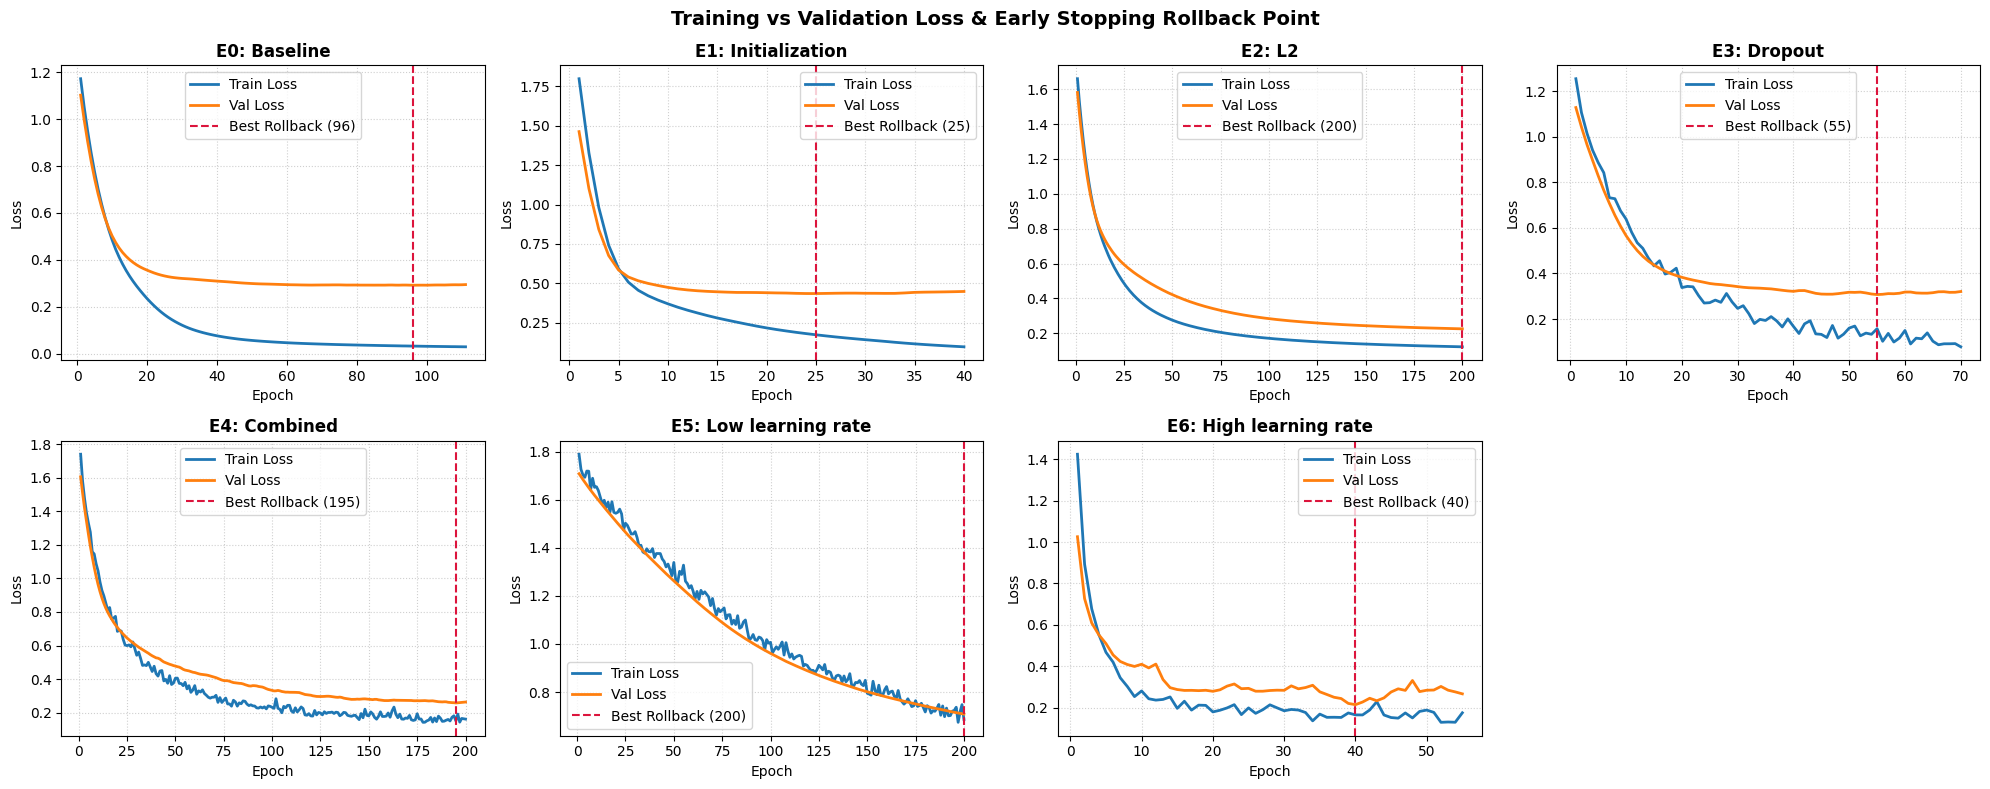

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, (name, h) in zip(axes, histories.items()):
    best_ep = int(np.argmin(h["val_loss"])) + 1
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="Train Loss", linewidth=2)
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="Val Loss", linewidth=2)
    ax.axvline(best_ep, color="crimson", linestyle="--", label=f"Best Rollback ({best_ep})")
    ax.set_title(name, fontweight="bold"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.legend(); ax.grid(True, linestyle=":", alpha=0.6)
axes[-1].axis("off")
plt.suptitle("Training vs Validation Loss & Early Stopping Rollback Point", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 8. Comparison Bar Charts

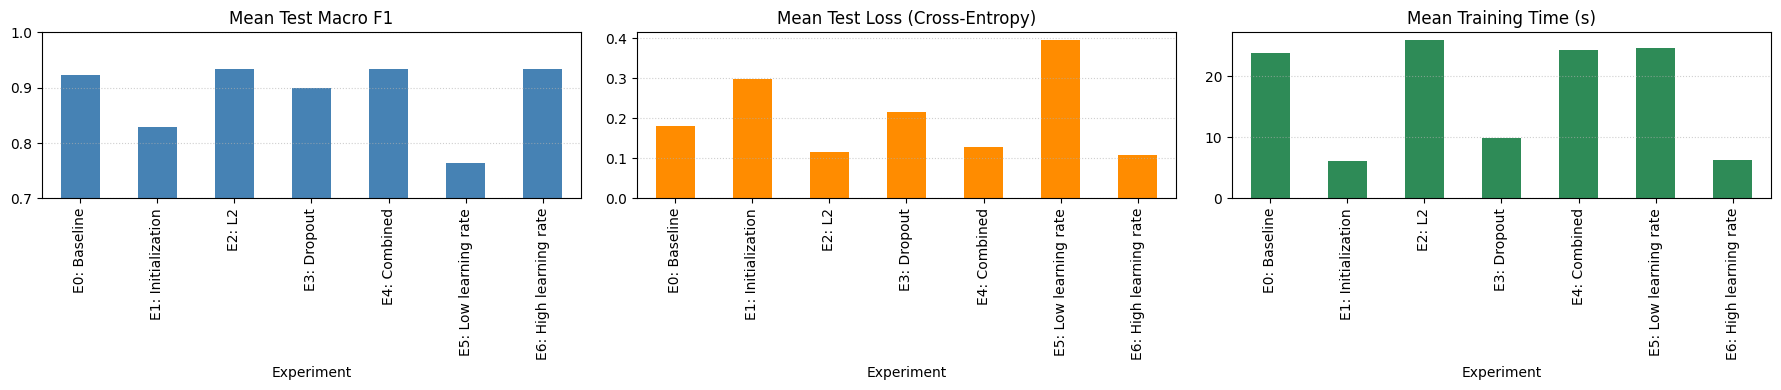

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
means["Test_macro_F1"].plot.bar(ax=axes[0], color="steelblue", title="Mean Test Macro F1"); axes[0].set_ylim(0.7, 1.0)
means["Test_loss"].plot.bar(ax=axes[1], color="darkorange", title="Mean Test Loss (Cross-Entropy)")
means["Time_s"].plot.bar(ax=axes[2], color="seagreen", title="Mean Training Time (s)")
for ax in axes: ax.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout(); plt.show()